# Qwen3-8B-Base role interventions

Three metrics: baseline agent preference, mean **agent − patient logit** after intervention, and prediction-flip frequency across intervention layers.

The fixed question is **Who or what is performing the action?** Prediction means the preferred answer among the agent and patient nouns, not the top token over the full vocabulary. Ties favor neither noun.

The four profiles edit the agent or patient token using pooled or voice-specific role means. Panels separate `test` / `gen_test` and active / passive sentences. Each layer is a separate intervention; logits are read at the final answer position after the forward pass, not at intermediate layers.

This notebook reads the completed Qwen3-8B-Base run on `active_pass_long`, using five-shot plain-text prompts. It needs no model weights or GPU.


In [4]:
%matplotlib inline
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").is_file(), "Run from the repository root or notebook directory"
RUN = ROOT / "ac-tpr-cache/qwen3-8b-base-active-pass-long-agent-fewshot-nnsight/interventions"
FIGURES_ROOT = ROOT / "notebook/figures/role_interventions_qwen3_base_active_pass_long"
metadata = json.loads((RUN / "metadata.json").read_text())
assert metadata["schema_version"] == 5
assert metadata["limit"] is None, "Use the completed full run, not a smoke run"

SPLITS = ["test", "gen_test"]
VOICES = ["active", "passive"]
GROUPS = ["split", "voice"]
CONDITIONS = ["mean_type", "edited_role"]
KEYS = GROUPS + ["layer"] + CONDITIONS
LAYERS = metadata["layer_indices"]
SENTENCE_KEYS = ["pair_id", "voice"]
SCORE_COLUMNS = ["baseline_agent_logit", "baseline_patient_logit"]
baseline_all = pd.read_csv(RUN / "baseline.csv")
results_all = pd.read_csv(
    RUN / "results.csv",
    usecols=["pair_id"] + KEYS + SCORE_COLUMNS
    + ["intervened_agent_logit", "intervened_patient_logit"],
)
assert len(baseline_all) == metadata["baseline_rows"]
assert len(results_all) == metadata["result_rows"]
assert not baseline_all.duplicated(SENTENCE_KEYS).any()
assert not results_all.duplicated(["pair_id"] + KEYS).any()
assert np.isfinite(baseline_all[SCORE_COLUMNS]).all().all()
assert np.isfinite(results_all[SCORE_COLUMNS + ["intervened_agent_logit", "intervened_patient_logit"]]).all().all()

FILTER_COLUMNS = [
    "subset", "verb_class", "np_type", "animacy_config", "animacy_hierarchy",
    "agent_animacy", "patient_animacy", "swapped",
]
display(pd.DataFrame([
    {"column": column, "value": value, "sentences": count}
    for column in FILTER_COLUMNS
    for value, count in baseline_all[column].value_counts().sort_index().items()
]))


,column,value,sentences
0,subset,mixed_contact,656
1,subset,names_agentive,628
2,subset,nouns_contact,812
3,verb_class,agentive,628
4,verb_class,contact,1468
5,np_type,mixed,656
6,np_type,name,628
7,np_type,noun,812
8,animacy_config,AA,1148
9,animacy_config,AI,374


## Select a subgroup

Edit `FILTERS` below, then rerun that cell and all following cells. `None` includes all values. For example, set `"subset": ["mixed_contact"]` to inspect that subgroup, or select several values in one list. Filters on different columns are combined with AND. The table above lists available values and full-run counts.

`AA`, `AI`, `IA`, and `II` describe **agent then patient** animacy (`A` = animate, `I` = inanimate). All tables and plots use only matching sentences. This filters saved interventions; the training role vectors remain those of the original full training split. Each selection exports to its own directory, recorded with the filters in `plot_metadata.json`.

In [5]:
# None includes every value; a list selects one or more values.
FILTERS = {
    "subset": ["mixed_contact"],# ["names_agentive"], ["nouns_contact"], ["mixed_contact"]
    "verb_class": None,         # ["agentive"], ["contact"]
    "np_type": None,            # ["name"], ["noun"], ["mixed"]
    "animacy_config": None,     # ["AA"], ["AI"], ["IA"], ["II"] (agent, patient)
    "animacy_hierarchy": None,  # ["equal"], ["aligned"], ["inverted"]
    "agent_animacy": None,      # ["animate"], ["inanimate"]
    "patient_animacy": None,    # ["animate"], ["inanimate"]
    "swapped": None,            # [0], [1]
}


In [6]:
baseline = baseline_all.copy()
active_filters = {}
for column, values in FILTERS.items():
    assert column in baseline_all.columns, f"Unknown filter column: {column}"
    if values is None:
        continue
    assert isinstance(values, list) and values, f"Use a nonempty list or None for {column}"
    assert set(values) <= set(baseline_all[column].unique()), f"Unknown values for {column}: {values}"
    baseline = baseline.loc[baseline[column].isin(values)].copy()
    active_filters[column] = values
assert not baseline.empty, "No sentences match FILTERS; change the selection"
results = results_all.merge(baseline[SENTENCE_KEYS], on=SENTENCE_KEYS, how="inner", validate="many_to_one")
assert len(results) == len(baseline) * len(LAYERS) * 4
FILTER_LABEL = "; ".join(f"{column}={','.join(map(str, values))}" for column, values in active_filters.items()) or "All sentences"
# Separate exports keep subgroup plots from overwriting the full-data view.
selection = json.dumps(active_filters, sort_keys=True)
folder = "all" if not active_filters else "filtered-" + hashlib.sha256(selection.encode()).hexdigest()[:12]
FIGURES = FIGURES_ROOT / folder
print("Selection:", FILTER_LABEL)
print(f"Selected {len(baseline):,} / {len(baseline_all):,} sentences")

# Every intervention must use the same baseline scores and split as its sentence.
matched = results.merge(
    baseline[SENTENCE_KEYS + ["split"] + SCORE_COLUMNS],
    on=SENTENCE_KEYS + ["split"], how="left", validate="many_to_one",
    suffixes=("", "_reference"),
)
for column in SCORE_COLUMNS:
    np.testing.assert_array_equal(matched[column], matched[f"{column}_reference"])
del matched

baseline["agent_minus_patient"] = baseline.baseline_agent_logit - baseline.baseline_patient_logit
results["baseline_agent_minus_patient"] = results.baseline_agent_logit - results.baseline_patient_logit
results["agent_minus_patient"] = results.intervened_agent_logit - results.intervened_patient_logit
before = results.baseline_agent_minus_patient
after = results.agent_minus_patient
results["prediction_flipped"] = ((before > 0) & (after < 0)) | ((before < 0) & (after > 0))
summary = results.groupby(KEYS).agg(
    sentences=("agent_minus_patient", "size"),
    mean_agent_minus_patient=("agent_minus_patient", "mean"),
    flips=("prediction_flipped", "sum"),
    flip_rate=("prediction_flipped", "mean"),
).reset_index()
expected_keys = pd.MultiIndex.from_tuples([
    (*group, layer, means, role)
    for group in baseline.groupby(GROUPS).groups
    for layer in LAYERS
    for means in ("pooled", "by_voice")
    for role in ("agent", "patient")
], names=KEYS)
assert summary.set_index(KEYS).index.sort_values().equals(expected_keys.sort_values())
assert summary.flip_rate.between(0, 1).all()
final_layer = results[results.layer == LAYERS[-1]]
np.testing.assert_array_equal(final_layer.agent_minus_patient, final_layer.baseline_agent_minus_patient)
assert not final_layer.prediction_flipped.any()

print(f"Model: {metadata['model']['name']} / {metadata['model']['revision']}")
print(f"Run: {RUN.resolve()}")
print(f"{len(baseline):,} sentences; {len(results):,} interventions; {len(LAYERS)} layers")


AssertionError: 

## Baseline agent preference

How many sentences have `baseline_agent_logit > baseline_patient_logit`? Counts and fractions use all sentences in each panel; ties do not count as agent wins.

In [ ]:
baseline_stats = baseline.groupby(GROUPS).agg(
    sentences=("agent_minus_patient", "size"),
    agent_wins=("agent_minus_patient", lambda values: (values > 0).sum()),
    mean_agent_minus_patient=("agent_minus_patient", "mean"),
).reindex(pd.MultiIndex.from_product([SPLITS, VOICES], names=GROUPS))
baseline_stats[["sentences", "agent_wins"]] = baseline_stats[["sentences", "agent_wins"]].fillna(0).astype(int)
baseline_stats["agent_preference"] = baseline_stats.agent_wins / baseline_stats.sentences
for group, rows in summary.groupby(GROUPS):
    assert (rows.sentences == baseline_stats.loc[group, "sentences"]).all()
display(baseline_stats[["sentences", "agent_wins", "agent_preference"]].round(4))
print(f"Overall agent preference: {baseline_stats.agent_wins.sum():,} / "
      f"{baseline_stats.sentences.sum():,} "
      f"({baseline_stats.agent_wins.sum() / baseline_stats.sentences.sum():.1%})")


sentences  agent_wins  agent_preference
split    voice                                           
test     active          40          40            1.0000
         passive         40          39            0.9750
gen_test active         288         288            1.0000
         passive        288         287            0.9965

Overall agent preference: 654 / 656 (99.7%)


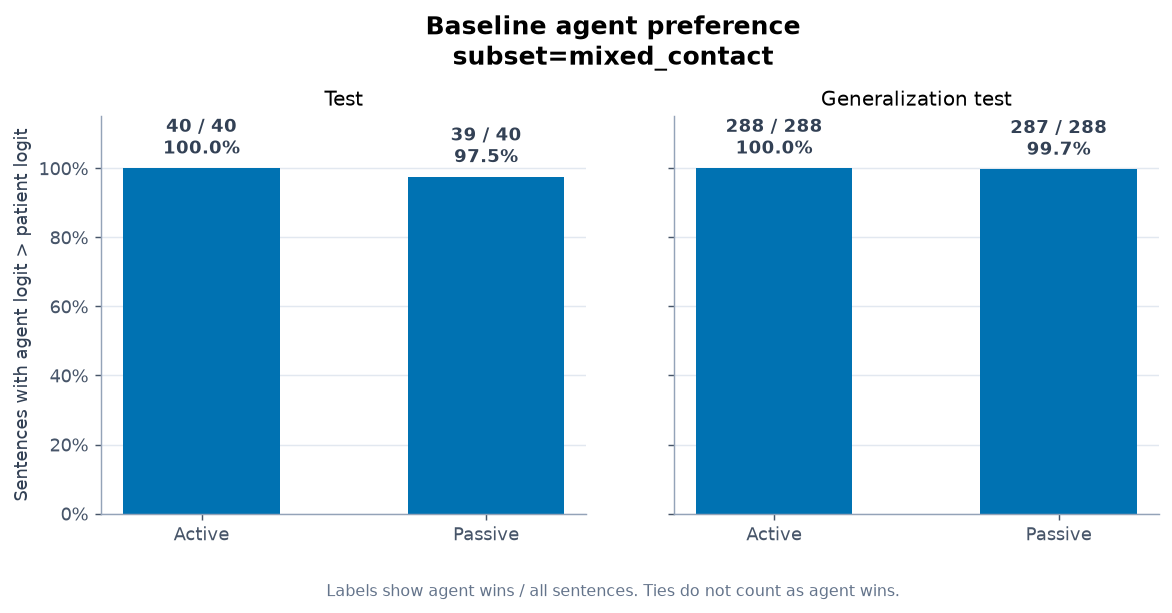

In [ ]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#94a3b8",
    "axes.labelcolor": "#334155",
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "figure.dpi": 130,
    "savefig.dpi": 200,
    "pdf.fonttype": 42,
})
COLORS = {"agent": "#0072B2", "patient": "#D55E00"}
STYLES = {"pooled": "-", "by_voice": "--"}
CONDITION_ORDER = [
    ("pooled", "agent"), ("pooled", "patient"),
    ("by_voice", "agent"), ("by_voice", "patient"),
]
CONDITION_LABELS = {
    (means, role): f"{role.capitalize()} edit / {'pooled' if means == 'pooled' else 'by voice'}"
    for means, role in CONDITION_ORDER
}
FIGURES.mkdir(parents=True, exist_ok=True)

def save_figure(fig, name):
    """Export the displayed figure as a raster preview and a vector PDF."""
    for extension in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{extension}", bbox_inches="tight")
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.7), sharey=True)
for ax, split in zip(axes, SPLITS):
    stats = baseline_stats.loc[split].reindex(VOICES)
    ax.bar(np.arange(2), stats.agent_preference, width=0.55, color=COLORS["agent"])
    for x, row in enumerate(stats.itertuples()):
        if row.sentences == 0:
            ax.text(x, 0.03, "No matching sentences", ha="center", va="bottom", fontsize=9)
            continue
        ax.text(x, row.agent_preference + 0.025,
                f"{row.agent_wins:,} / {row.sentences:,}\n{row.agent_preference:.1%}",
                ha="center", va="bottom", color="#334155", weight="bold")
    ax.set_title("Test" if split == "test" else "Generalization test")
    ax.set_xticks(range(2), [voice.capitalize() for voice in VOICES])
    ax.set_ylim(0, 1.15)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#e2e8f0")
axes[0].set_ylabel("Sentences with agent logit > patient logit")
fig.suptitle(f"Baseline agent preference\n{FILTER_LABEL}", fontsize=14, weight="bold", y=0.99)
fig.text(0.5, 0.035, "Labels show agent wins / all sentences. Ties do not count as agent wins.",
         ha="center", color="#64748b", fontsize=9)
fig.subplots_adjust(top=0.82, bottom=0.17, wspace=0.18)
save_figure(fig, "baseline_preferences")


## Agent − patient logits by intervention layer

Mean final-answer logit difference for each of the four profiles. Positive values favor the agent. The dotted line is the unedited baseline mean. All sentences contribute.

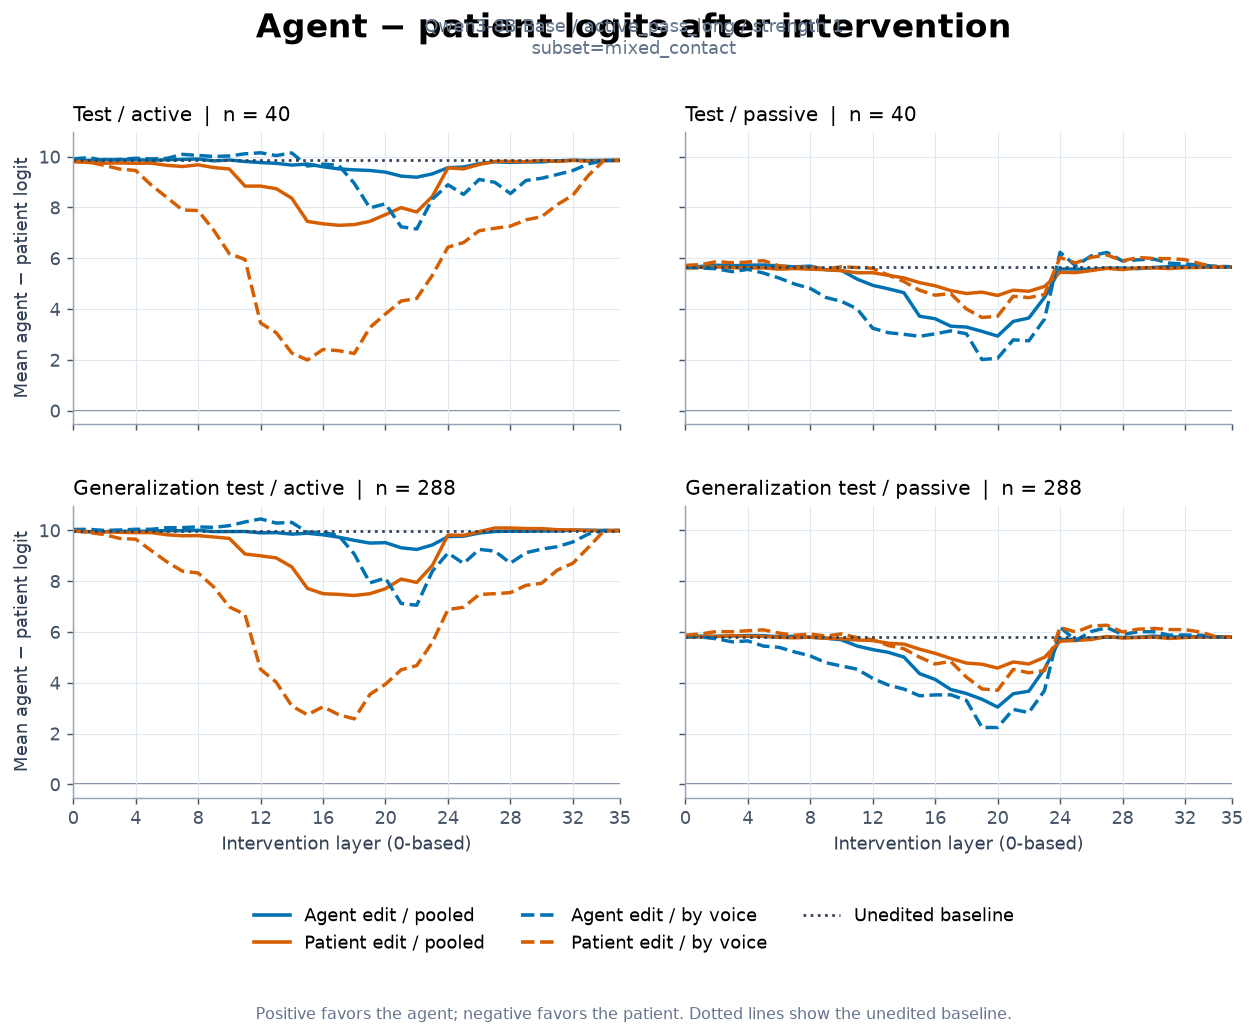

In [ ]:
def plot_layers(metric, title, ylabel, filename, footnote, *, reference=False, percent=False):
    """Compare four edit conditions using common axes across split/voice panels."""
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 8), sharex=True, sharey=True)
    for row_index, split in enumerate(SPLITS):
        for col_index, voice in enumerate(VOICES):
            ax = axes[row_index, col_index]
            data = summary[(summary.split == split) & (summary.voice == voice)]
            stats = baseline_stats.loc[(split, voice)]
            if stats.sentences == 0:
                ax.text(0.5, 0.5, f"{split} / {voice}\nNo matching sentences", ha="center", va="center", transform=ax.transAxes)
                ax.set_axis_off()
                continue
            for means, role in CONDITION_ORDER:
                line = data[(data.mean_type == means) & (data.edited_role == role)].sort_values("layer")
                assert line.layer.tolist() == LAYERS
                ax.plot(line.layer, line[metric], color=COLORS[role],
                        linestyle=STYLES[means], linewidth=1.9)
            ax.axhline(0, color="#64748b", linewidth=0.9, zorder=0)
            if reference:
                ax.axhline(stats.mean_agent_minus_patient, color="#334155", linestyle=":",
                           linewidth=1.5)
            split_title = "Test" if split == "test" else "Generalization test"
            denominator = f"n = {int(stats.sentences):,}"
            ax.set_title(f"{split_title} / {voice}  |  {denominator}", loc="left")
            ax.set_xlim(LAYERS[0], LAYERS[-1])
            ax.set_xticks(sorted(set(LAYERS[::4] + [LAYERS[-1]])))
            ax.grid(color="#e2e8f0", linewidth=0.65)
            ax.set_axisbelow(True)
            if percent:
                ax.set_ylim(0, min(1, max(0.05, np.ceil(summary[metric].max() / 0.05) * 0.05)))
                ax.yaxis.set_major_formatter(PercentFormatter(1))
            if row_index == 1:
                ax.set_xlabel("Intervention layer (0-based)")
            if col_index == 0:
                ax.set_ylabel(ylabel)
    handles = [
        Line2D([0], [0], color=COLORS[role], linestyle=STYLES[means],
               linewidth=2, label=CONDITION_LABELS[(means, role)])
        for means, role in CONDITION_ORDER
    ]
    if reference:
        handles.append(Line2D([0], [0], color="#334155", linestyle=":",
                              linewidth=1.5, label="Unedited baseline"))
    fig.suptitle(title, fontsize=18, weight="bold", y=0.985)
    fig.text(0.5, 0.945, f"Qwen3-8B-Base / active_pass_long / strength 1\n{FILTER_LABEL}",
             ha="center", color="#64748b", fontsize=10)
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.065),
               ncol=2 if not reference else 3, frameon=False, fontsize=10)
    fig.text(0.5, 0.017, footnote, ha="center", color="#64748b", fontsize=9)
    fig.subplots_adjust(top=0.87, bottom=0.23, hspace=0.28, wspace=0.12)
    save_figure(fig, filename)

plot_layers(
    "mean_agent_minus_patient",
    "Agent − patient logits after intervention",
    "Mean agent − patient logit",
    "answer_scores",
    "Positive favors the agent; negative favors the patient. Dotted lines show the unedited baseline.",
    reference=True,
)


["Jhon", "kick", "the ball"] → agent = "Jhon", patient = "the ball"  
Jhon - agent_active_centroids + patient_active_centroids

["the ball", "is kicked", "by", "john"] → agent = "Jhon", patient = "the ball"  
Jhon - agent_passive_centroids + patient_passive_centroids

## Prediction-flip frequency by intervention layer

A flip is a strict change from agent preference to patient preference **or vice versa**. Frequency is the number of flips divided by **all sentences** in the panel, computed from individual intervention results. A tie before or after intervention is not a flip.

The last layer is a control: editing a noun after the final block cannot affect the answer position through later attention, so its flip frequency is zero.

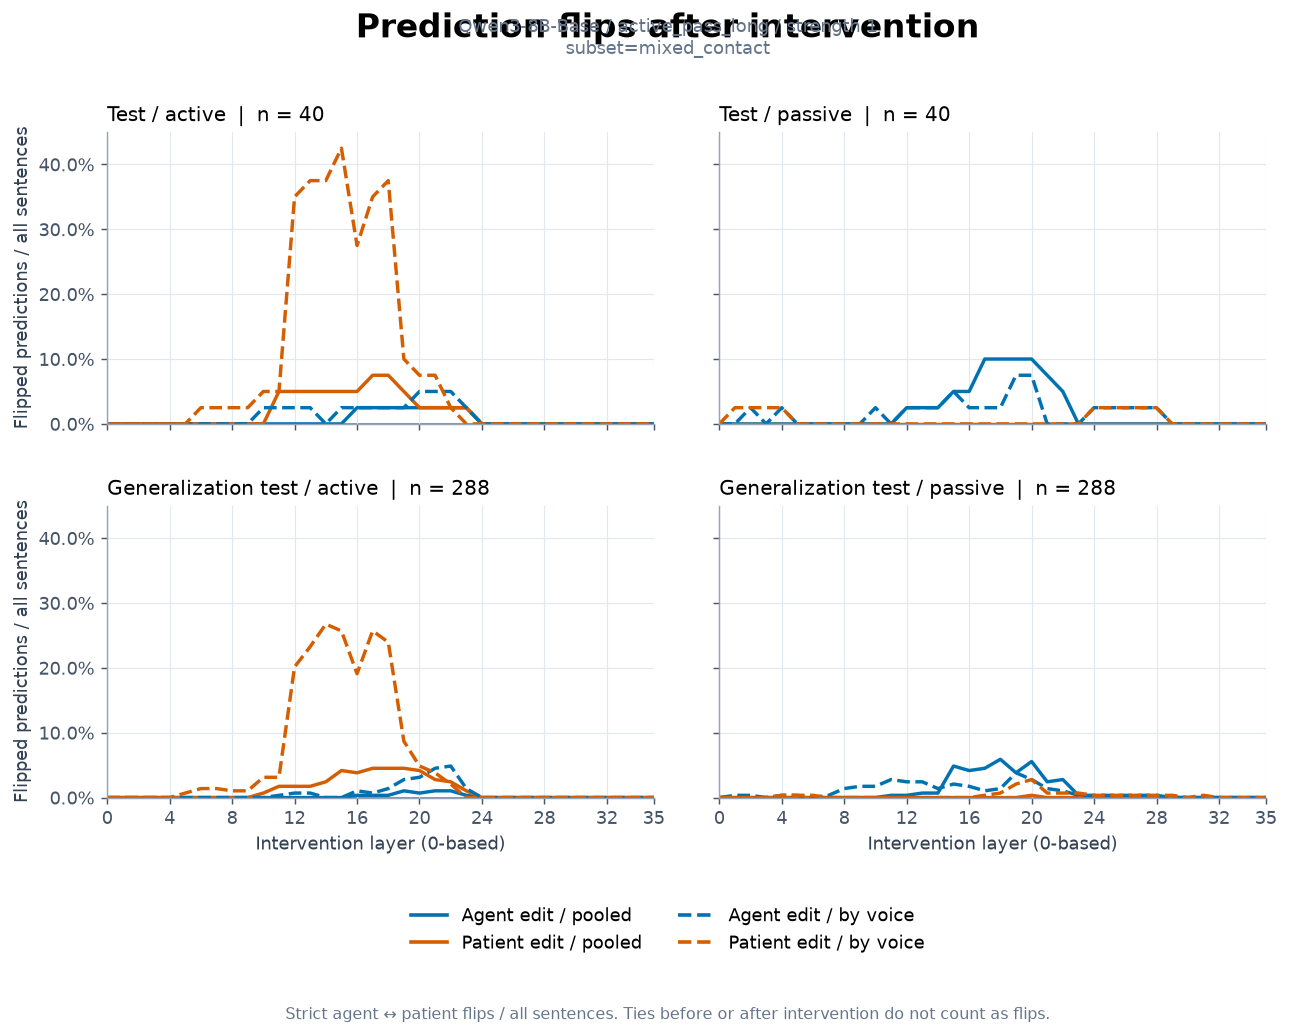

In [ ]:
plot_layers(
    "flip_rate",
    "Prediction flips after intervention",
    "Flipped predictions / all sentences",
    "prediction_flips",
    "Strict agent ↔ patient flips / all sentences. Ties before or after intervention do not count as flips.",
    percent=True,
)


## Export

Save the counts and plotted means/rates with source hashes. Curves describe this fixed corpus; no uncertainty intervals are estimated.

In [ ]:
baseline_stats[["sentences", "agent_wins", "agent_preference"]].to_csv(
    FIGURES / "baseline_statistics.csv"
)
summary.to_csv(FIGURES / "layer_statistics.csv", index=False)
provenance = {
    "filters": active_filters,
    "selected_sentences": len(baseline),
    "run_directory": str(RUN.resolve()),
    "run_created_at": metadata["created_at"],
    "model": metadata["model"],
    "execution_model": metadata["execution_model"],
    "schema_version": metadata["schema_version"],
    "source_sha256": {
        name: hashlib.sha256((RUN / name).read_bytes()).hexdigest()
        for name in ("metadata.json", "baseline.csv", "results.csv")
    },
    "baseline_preference": "count(baseline_agent_logit > baseline_patient_logit) / all sentences",
    "answer_score": "mean(intervened_agent_logit - intervened_patient_logit)",
    "prediction_flip_rate": "strict agent-to-patient or patient-to-agent preference flips / all sentences",
    "ties": "Ties before or after intervention do not count as flips; all sentences remain in the denominator",
    "uncertainty": "Descriptive curves; no uncertainty intervals",
}
(FIGURES / "plot_metadata.json").write_text(json.dumps(provenance, indent=2) + "\n")
print(f"Figures and tables saved to {FIGURES}")


Figures and tables saved to /orfeo/cephfs/home/dssc/zenocosini/AC-TPR-project/notebook/figures/role_interventions_qwen3_base_active_pass_long/filtered-2b290ed3471b
